In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
gt_path = 'train_data/train_gt.csv'
wl_path = 'train_data/wavelengths.csv'


gt_df = pd.read_csv(gt_path)
wave_lengths = pd.read_csv(wl_path)

In [24]:
#Loading example file, gaining insights about the data

img_no = 1200

path = f'train_data/train_data/{img_no}.npz'

#axis 0 - band index, 1 - spectral image height, 2 - spectral image width
with np.load(path) as npz:
    spectral_arr = np.ma.MaskedArray(**npz)

bands, height, width = spectral_arr.shape

print(f'Bands = {bands}, height = {height}, width = {width}')
print(f'Data type: {spectral_arr.dtype}')
print(f'Max val = {spectral_arr.max()}, min val = {spectral_arr.min()}')



Bands = 150, height = 107, width = 101
Data type: int16
Max val = 4901, min val = 278


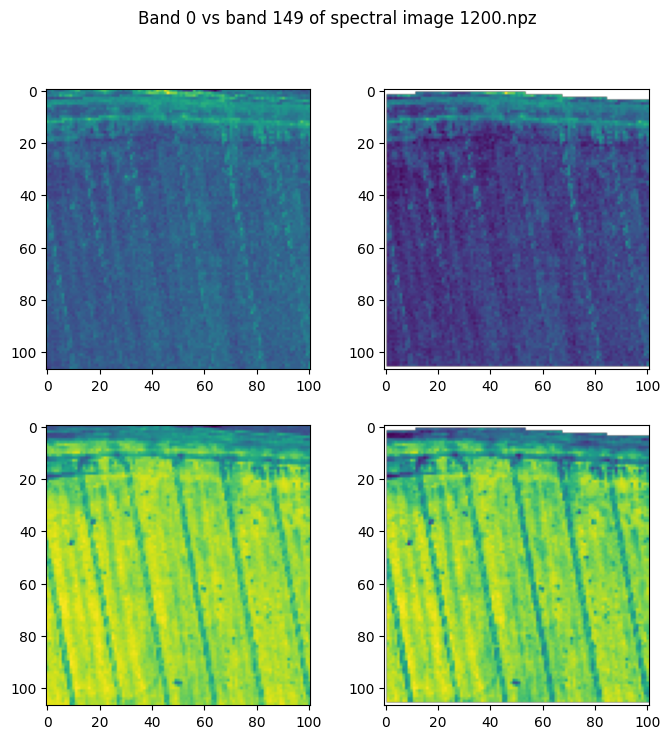

In [25]:
#Plotting with & without binary mask
fig, ax = plt.subplots(2,2, figsize=(8,8))

ax[0,0].imshow(spectral_arr[0,:,:].data)
ax[0,1].imshow(spectral_arr[0,:,:])

ax[1,0].imshow(spectral_arr[149,:,:].data)
ax[1,1].imshow(spectral_arr[149,:,:])

plt.suptitle(f'Band 0 vs band 149 of spectral image {img_no}.npz')
plt.show()

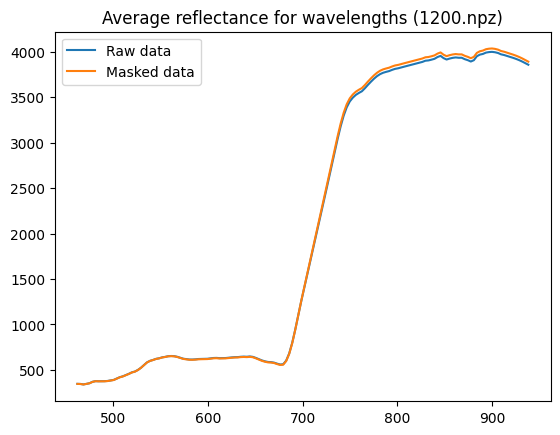

In [26]:
#Plotting spectral reflectance of the example image
spectral_reflectances_masked = [spectral_arr[i,:,:].mean() for i in range(bands)]
spectral_reflectances_raw = [spectral_arr[i,:,:].data.mean() for i in range(bands)]

plt.plot(wave_lengths['wavelength'], spectral_reflectances_raw, label = "Raw data")
plt.plot(wave_lengths['wavelength'], spectral_reflectances_masked, label = "Masked data")
plt.title(f'Average reflectance for wavelengths ({img_no}.npz)')
plt.legend()
plt.show()

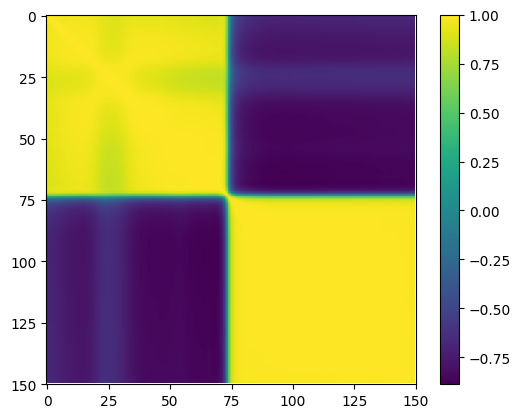

In [27]:
#Calculating correlation between bands of the example image
image_flat = spectral_arr.reshape(bands, -1)
corr = np.corrcoef(image_flat)

plt.imshow(corr, cmap='viridis')
plt.colorbar()
plt.xticks(range(0,bands+1,25))
plt.yticks(range(0,bands+1,25))
plt.show()

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [31]:
#Preparing data for PCA (of the example image)
X = spectral_arr.data.reshape(bands, -1).T #(width * height, bands) transposed

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_transformed = pca.fit_transform(X_scaled)

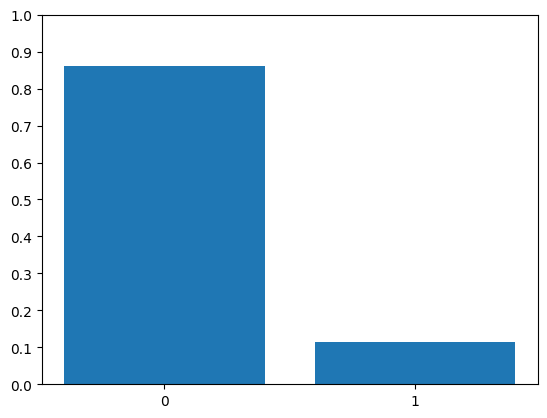

In [32]:
plt.bar(range(pca.n_components_), pca.explained_variance_ratio_)
plt.xticks(range(pca.n_components_))
plt.yticks(np.arange(0,1.1,0.1))
plt.show()

In [33]:
#first principal component
pc1 = pca.components_[0]
pc2 = pca.components_[1]

print(pca.components_.shape)

(2, 150)


In [35]:
#PCA for almost whole dataset (step = 10 - every 10th image)
X_total = []

for i in range(0,1701,10):
    with np.load(f'train_data/train_data/{i}.npz') as npz:
        arr = np.ma.MaskedArray(**npz)

    x = arr.data.reshape(arr.shape[0], -1).T #(width * height, bands)
    mask = arr.mask.reshape(arr.shape[0], -1).T

    #including binary mask
    x_valid = x[~mask.any(axis=1)]
    X_total.append(x_valid)

X_total = np.vstack(X_total)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_total)

pca = PCA(n_components=10)
X_transformed = pca.fit_transform(X_scaled)

print(pca.explained_variance_ratio_.cumsum())


[0.67130931 0.9902943  0.99610577 0.99892918 0.9991785  0.99935485
 0.99944833 0.99951335 0.99957001 0.99961949]


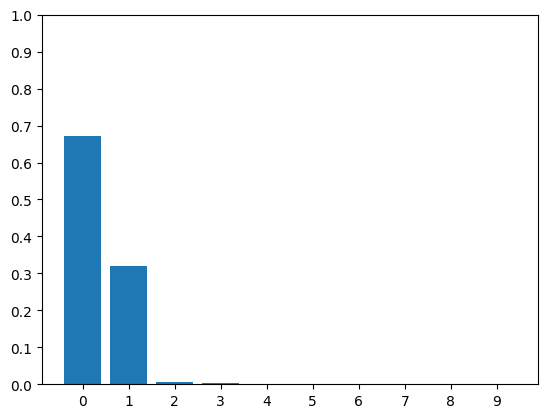

In [36]:
#Plotting variance ratios of every Prinicpal Component - there are 2 PC's that explain >= 95% of the data variance
plt.bar(range(pca.n_components_), pca.explained_variance_ratio_)
plt.xticks(range(pca.n_components_))
plt.yticks(np.arange(0,1.1,0.1))
plt.show()

In [49]:
import matplotlib.pyplot as plt
import numpy as np

def plot_pca_loadings(pca_model, wavelengths=None, n_components=3):
    """
    Visualizes PCA loadings (eigenvectors) to show band influence.
    """
    loadings = pca_model.components_

    n_bands = loadings.shape[1]

    if wavelengths is None:
        x_axis = np.arange(n_bands)
        x_label = "Band Index"
    else:
        if len(wavelengths) != n_bands:
            print(f"WARNING: Length of wavelengths list ({len(wavelengths)}) does not match number of bands in PCA ({n_bands}). Using indices.")
            x_axis = np.arange(n_bands)
            x_label = "Band Index"
        else:
            x_axis = wavelengths
            x_label = "Wavelength [nm]"

    plt.figure(figsize=(14, 6))

    colors = ['blue', 'orange', 'green', 'red', 'purple']

    for i in range(n_components):
        c = colors[i % len(colors)]
        plt.plot(x_axis, loadings[i, :], label=f'PC {i+1}', color=c, linewidth=1.5)

        max_idx = np.argmax(np.abs(loadings[i, :]))
        plt.scatter(x_axis[max_idx], loadings[i, max_idx], color=c, s=50, zorder=5)

    plt.axhline(0, color='black', linestyle='--', linewidth=0.8, alpha=0.7)

    plt.title(f'PCA Loadings: Band Influence on First {n_components} Components', fontsize=14)
    plt.xlabel(x_label, fontsize=12)
    plt.ylabel('Loading Value (Eigenvector Coefficient)', fontsize=12)
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

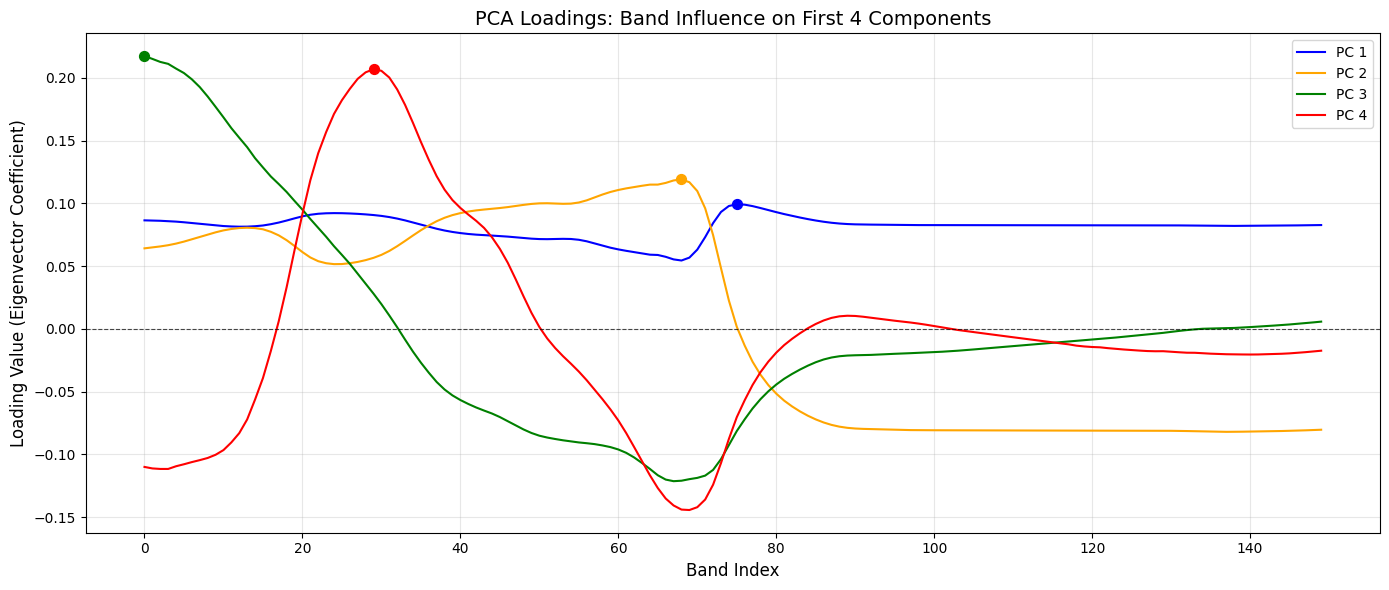

In [50]:
plot_pca_loadings(pca, wavelengths=None, n_components=4)

Dostępne kolumny: Index(['sample_index', 'P', 'K', 'Mg', 'pH'], dtype='object')
Liczba wierszy w GT: 1732
Liczba wierszy w PCA: 536947
